# 03 Forecast and error analysis

Train the final model once on the training file, write the submission, then check accuracy, turning points and where the forecast goes wrong.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src import config
from src.data import load_all
from src.evaluate import (accuracy_table, actual_price_ahead, direction_hit_rate,
                          reversal_scores, turning_point_calls)
from src.features import FEATURES, build_candidate_features, build_features, curve_slope, storage_surplus
from src.model import coefficients, forecast_all_horizons, futures_curve_forecast, no_change_forecast
from src.run_pipeline import save_submission

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

data = load_all()
features = build_features(data)
test_dates = data.index[data["is_test"]]

## Train

Only months whose outcome was known by August 2020 are used. The model isn't updated during the test period.

In [2]:
forecasts, models = forecast_all_horizons(data, features, train_end=config.TRAIN_END)
coefficients(models, FEATURES).round(2)

,month_end_move,price_change_1m,oil_change_3m,usual_gap_to_futures
1m ahead,0.58,-0.29,0.08,-0.01
2m ahead,0.42,-0.20,0.17,-0.05
3m ahead,0.46,-0.23,0.19,-0.06


The weights are in the features' own units (the scaling is undone in coefficients). The features are log changes, so for moderate moves they read roughly like percentages. 

## Submission

In [3]:
submission = save_submission(forecasts, test_dates)
submission.head()

,pred_1,pred_2,pred_3
date,,,
2020-09-30,2.584027,2.926687,2.945883
2020-10-31,3.161359,3.137884,3.027075
2020-11-30,2.648015,2.645420,2.508497
2020-12-31,2.459965,2.450762,2.404633
2021-01-31,2.673430,2.695721,2.703967


First row: on 30 Sep 2020 the forecast is 2.58 for October, 2.93 for November and 2.95 for December 2020.

In [4]:
example = pd.read_csv(config.RAW_DIR / "submission_example.csv")
written = pd.read_csv(config.OUTPUT_DIR / "submission.csv")

print("rows:", len(written))
print("same columns:", list(written.columns) == list(example.columns))
print("same dates:", written["date"].equals(example["date"]))
print("no missing values:", not written.isna().any().any())

rows: 48
same columns: True
same dates: True
no missing values: True


I also wanted to be sure that nothing looks into the future. For each test date I cut off all the data after it and run everything again. If any feature used future data, the forecast would change.

In [5]:
max_diff = 0.0
for date in test_dates:
    known = data.loc[:date]
    blind, _ = forecast_all_horizons(known, build_features(known), train_end=config.TRAIN_END)
    max_diff = max(max_diff, (blind.loc[date] - forecasts.loc[date]).abs().max())

print("largest change when the future is removed:", max_diff)

largest change when the future is removed: 0.0


0.0, so no leakage.

## Accuracy on the test period

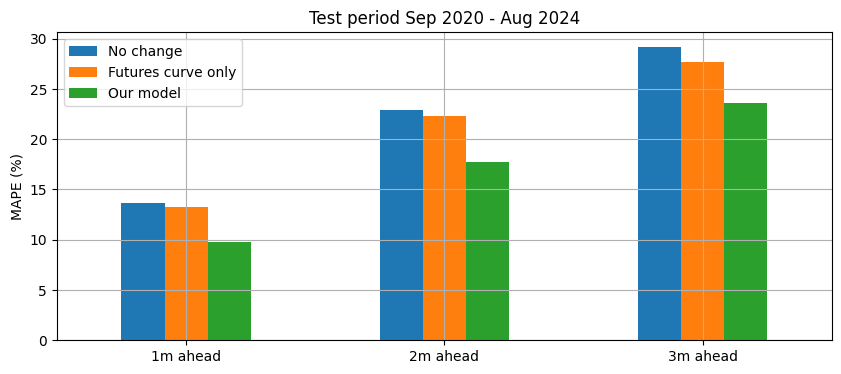

,1m ahead,2m ahead,3m ahead,average
No change,13.65,22.92,29.18,21.91
Futures curve only,13.22,22.32,27.72,21.09
Our model,9.82,17.69,23.61,17.04


In [6]:
no_change, curve = no_change_forecast(data), futures_curve_forecast(data)
accuracy = accuracy_table(data, {"No change": no_change, "Futures curve only": curve, "Our model": forecasts}, test_dates)

accuracy.drop(columns="average").T.plot.bar(rot=0)
plt.ylabel("MAPE (%)")
plt.title("Test period Sep 2020 - Aug 2024")
plt.show()

accuracy.round(2)

In [7]:
for h in config.HORIZONS:
    scored = actual_price_ahead(data, h).loc[test_dates].notna().sum()
    print(f"{h} month(s) ahead: {scored} of {len(test_dates)} forecasts can be scored")

1 month(s) ahead: 47 of 48 forecasts can be scored
2 month(s) ahead: 46 of 48 forecasts can be scored
3 month(s) ahead: 45 of 48 forecasts can be scored


MAPE is 9.8% at 1 month, 17.7% at 2 months and 23.6% at 3 months. That's 19-28% lower than no change at every horizon, similar to what I saw in validation.

The errors are about twice as large as in validation (8.35%), but the baselines double as well (10.4% to 21.9%), so it's mostly the test period being much more volatile.

The last few forecasts can't be scored because their target months (Sep-Nov 2024) are after the end of the data. They're still in the submission.

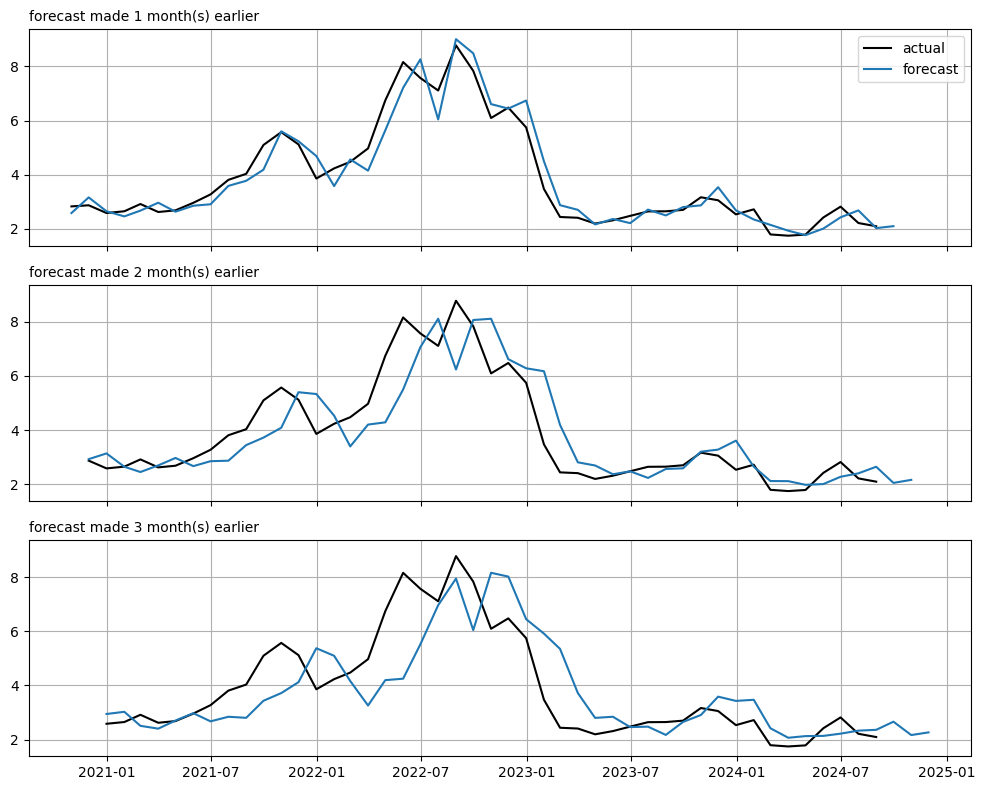

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, h in zip(axes, config.HORIZONS):
    target_month = test_dates + pd.offsets.MonthEnd(h)   # plot each forecast at the month it is for
    ax.plot(target_month, data["target"].reindex(target_month), color="black", label="actual")
    ax.plot(target_month, forecasts.loc[test_dates, f"pred_{h}"], label="forecast")
    ax.set_title(f"forecast made {h} month(s) earlier", loc="left", fontsize=10)
axes[0].legend()
plt.tight_layout()
plt.show()

At 1 month the forecast follows the price quite closely. At 2 and 3 months it lags behind the big moves of 2022, which neither the model nor the futures market saw coming that early.

## Direction and turning points

In [9]:
pd.DataFrame({"Our model (%)": direction_hit_rate(data, forecasts, test_dates),
              "Futures curve only (%)": direction_hit_rate(data, curve, test_dates)}).round(0)

,Our model (%),Futures curve only (%)
1m ahead,70.0,51.0
2m ahead,65.0,50.0
3m ahead,64.0,64.0


A turning point here is a month that is the highest (peak) or lowest (trough) price within 2 months on each side. The model gets it right if its 1-month forecast made in that month points the right way (down after a peak, up after a trough).

turning points: 13
called by the model: 8
called by futures curve only: 5


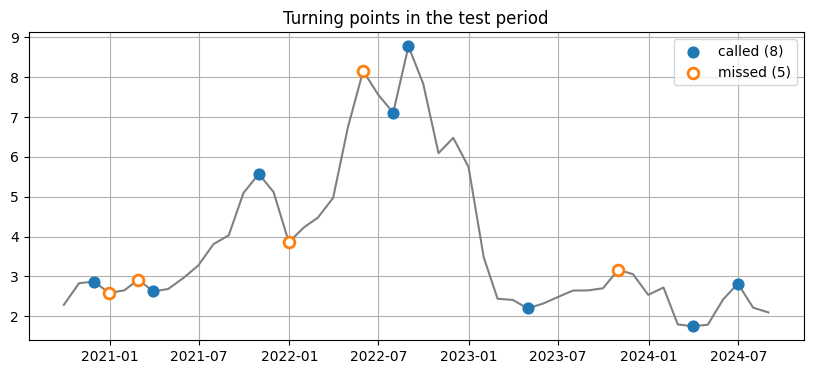

In [10]:
calls = turning_point_calls(data, forecasts, test_dates)
curve_calls = turning_point_calls(data, curve, test_dates)
print("turning points:", len(calls))
print("called by the model:", calls["called"].sum())
print("called by futures curve only:", curve_calls["called"].sum())

hit, miss = calls[calls["called"]], calls[~calls["called"]]
fig, ax = plt.subplots()
ax.plot(data.loc[test_dates, "target"], color="grey")
ax.scatter(hit.index, hit["price"], s=60, color="tab:blue", zorder=3, label=f"called ({len(hit)})")
ax.scatter(miss.index, miss["price"], s=60, facecolor="white", edgecolor="tab:orange", linewidth=2, zorder=3,
           label=f"missed ({len(miss)})")
ax.set_title("Turning points in the test period")
ax.legend()
plt.show()

Stricter version, counting every month where the price changes direction:

In [11]:
pd.DataFrame({"Our model": reversal_scores(data, forecasts, test_dates),
              "Futures curve only": reversal_scores(data, curve, test_dates)})

,Our model,Futures curve only
months,47,47
real_reversals,18,18
called_reversals,18,22
correct_calls,11,9


The price changed direction in 18 of 47 months. The model predicted a change in 18 months and 11 were right. The futures curve predicted 22 and 9 were right.

## Why the turning points happened

Market situation at each turning point next to what the model saw. The features are log changes, `np.expm1(x) * 100` turns them back into normal %.

In [12]:
context = pd.DataFrame({
    "type": calls["type"],
    "price": calls["price"],
    "storage_vs_5y_avg_tcf": storage_surplus(data),
    "lng_exports_bcf_per_day": data["lng_exports"] / data.index.days_in_month / 1000,
    "europe_gas_price": data["europe_gas"],
    "market_ended_month_pct": np.expm1(features["month_end_move"]) * 100,
    "monthly_average_moved_pct": np.expm1(features["price_change_1m"]) * 100,
    "futures_curve_next_month_pct": np.expm1(curve_slope(data, 1)) * 100,
    "forecast_next_month": calls["forecast_next_month"],
    "actual_next_month": calls["actual_next_month"],
    "called": calls["called"],
})
context.loc[calls.index].round(2)

,type,price,storage_vs_5y_avg_tcf,lng_exports_bcf_per_day,europe_gas_price,market_ended_month_pct,monthly_average_moved_pct,futures_curve_next_month_pct,forecast_next_month,actual_next_month,called
date,,,,,,,,,,,
2020-11-30,peak,2.87,0.31,9.36,4.78,-16.92,1.46,4.18,2.65,2.58,True
2020-12-31,trough,2.58,0.19,9.81,5.83,-12.88,-9.95,0.00,2.46,2.65,False
2021-02-28,peak,2.92,-0.13,7.44,6.17,9.29,10.11,-1.71,2.97,2.62,False
2021-03-31,trough,2.62,-0.01,10.36,6.21,-7.16,-10.11,1.53,2.63,2.68,True
2021-10-31,peak,5.57,-0.02,9.62,29.81,-9.82,9.31,2.87,5.23,5.12,True
2021-12-31,trough,3.86,0.16,11.14,37.36,-19.30,-24.63,-1.81,3.58,4.23,False
2022-05-31,peak,8.16,-0.27,11.34,27.46,10.74,20.98,0.86,8.26,7.57,False
2022-07-31,trough,7.11,-0.27,9.69,51.15,52.61,-6.10,-1.25,9.01,8.78,True
2022-08-31,peak,8.78,-0.29,9.68,69.98,10.78,23.47,-0.11,8.48,7.84,True


A few examples:
Oct 2021 (peak): the market ended October 10% lower while the monthly average was still up 9%. The model forecast a fall of 6%, the price fell 8%. Called.
May 2022 (peak): nothing in the data pointed down. In June a fire at the Freeport LNG export terminal cut exports, so more gas stayed in the US and the price fell. Missed, an accident can’t be forecast.
Apr 2023 (trough): after a mild winter storage was 0.4 Tcf above normal, and the futures curve already priced next month 8% higher. Called.
So the model catches turns that already started inside the month (the month-end price is far from the average) or that the futures curve expects. It misses turns caused by things that happen after the forecast date, like weather or accidents.


## Errors

In [13]:
detail = pd.DataFrame({"price": data.loc[test_dates, "target"]})
for h in config.HORIZONS:
    detail[f"actual_{h}"] = actual_price_ahead(data, h).loc[test_dates]
    detail[f"pred_{h}"] = forecasts.loc[test_dates, f"pred_{h}"]
    detail[f"error_pct_{h}"] = (detail[f"pred_{h}"] / detail[f"actual_{h}"] - 1) * 100

error_cols = ["error_pct_1", "error_pct_2", "error_pct_3"]
by_year = detail[error_cols].abs().groupby(detail.index.year).mean()
by_year.index.name = "forecast made in"
by_year.round(1)

,error_pct_1,error_pct_2,error_pct_3
forecast made in,,,
2020,7.1,9.9,12.6
2021,9.0,17.0,21.8
2022,11.4,27.6,38.4
2023,8.5,11.3,18.2
2024,12.4,17.1,14.0


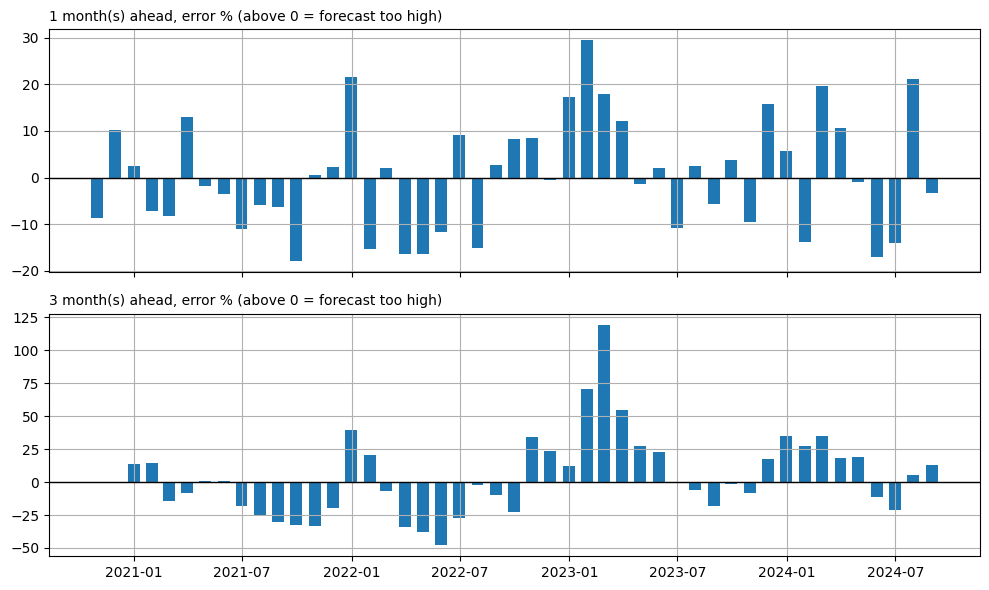

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, h in zip(axes, (1, 3)):
    err = detail[f"error_pct_{h}"].dropna()
    ax.bar(err.index + pd.offsets.MonthEnd(h), err, width=20)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{h} month(s) ahead, error % (above 0 = forecast too high)", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

The errors come in blocks. Mid-2021 to mid-2022 the forecasts were too low because the price kept climbing. Late 2022 to spring 2023 they were way too high when the price collapsed, and winter 2023-2024 was too high again but less. 2022 is the worst year at every horizon.

5 biggest misses at 3 months:

In [15]:
worst = detail["error_pct_3"].abs().sort_values(ascending=False).index[:5]
table = detail.loc[worst, ["price", "pred_3", "actual_3", "error_pct_3"]].copy()
table["futures_curve_3"] = curve.loc[worst, "pred_3"]
table.round(2)

,price,pred_3,actual_3,error_pct_3,futures_curve_3
date,,,,,
2022-11-30,6.48,5.35,2.44,119.46,5.78
2022-10-31,6.09,5.92,3.47,70.40,6.42
2022-12-31,5.75,3.72,2.41,54.36,4.65
2022-02-28,4.47,4.25,8.16,-47.92,4.47
2021-09-30,5.10,5.37,3.86,39.30,5.29


In all five the futures market missed in the same direction by a similar amount. For example on 30 Nov 2022 the futures implied 5.8 for February 2023, the model said 5.3, and the actual price was 2.4 after a mild winter.

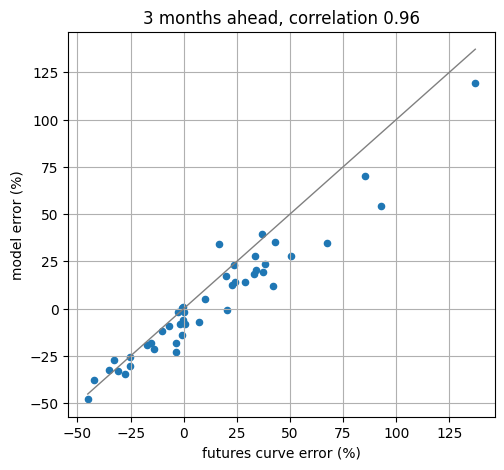

In [16]:
model_err = detail["error_pct_3"]
market_err = (curve.loc[test_dates, "pred_3"] / detail["actual_3"] - 1) * 100

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(market_err, model_err, s=20)
line = [market_err.min(), market_err.max()]
ax.plot(line, line, color="grey", linewidth=1)
ax.set_xlabel("futures curve error (%)")
ax.set_ylabel("model error (%)")
ax.set_title(f"3 months ahead, correlation {model_err.corr(market_err):.2f}")
plt.show()

In [17]:
print("average error with sign (above 0 = too high):")
print(detail[error_cols].mean().round(1).to_string())

average error with sign (above 0 = too high):
error_pct_1    0.3
error_pct_2    3.0
error_pct_3    4.1


The big errors of the model are basically the market's own surprises (correlation 0.96). The model does better than the futures curve on average, but it can't see things the market didn't see either.

At 1 month there's no real bias (+0.3%). At 2 and 3 months the forecasts were 3-4% too high on average, mostly because of the 2023 crash. Accuracy drops with the horizon because the two main features describe where the market is now, and that information is mostly used up after a month.

## Other models on the test period (checked after choosing)

I chose the model in model selection notebook using only the training file. After that I was curious how the other linear models from model selection would have done on the test period. They are trained the same way (once, on data up to Aug 2020). This is only a check, I didn't use it to change the model.

In [18]:
def lasso():
    return make_pipeline(StandardScaler(), Lasso(alpha=0.01))


def elastic_net():
    return make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5))


all_features = features.join(build_candidate_features(data))   # 3 + 12 = 15 features

others = {
    "No change": no_change,
    "Futures curve only": curve,
    "Our model (ridge, 3 features)": forecasts,
    "Ridge, 15 features": forecast_all_horizons(data, all_features, config.TRAIN_END)[0],
    "Lasso, 3 features": forecast_all_horizons(data, features, config.TRAIN_END, lasso)[0],
    "Lasso, 15 features": forecast_all_horizons(data, all_features, config.TRAIN_END, lasso)[0],
    "Elastic net, 3 features": forecast_all_horizons(data, features, config.TRAIN_END, elastic_net)[0],
    "Elastic net, 15 features": forecast_all_horizons(data, all_features, config.TRAIN_END, elastic_net)[0],
}
accuracy_table(data, others, test_dates).round(2)

/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/min

,1m ahead,2m ahead,3m ahead,average
No change,13.65,22.92,29.18,21.91
Futures curve only,13.22,22.32,27.72,21.09
"Our model (ridge, 3 features)",9.82,17.69,23.61,17.04
"Ridge, 15 features",9.55,17.19,23.07,16.60
"Lasso, 3 features",10.13,18.16,23.88,17.39
"Lasso, 15 features",10.14,17.90,23.28,17.11
"Elastic net, 3 features",9.85,17.76,23.67,17.10
"Elastic net, 15 features",9.78,17.42,23.06,16.75


In [19]:
# which features lasso keeps when it is trained on the whole training file
_, lasso_models = forecast_all_horizons(data, all_features, config.TRAIN_END, lasso)
for h, m in lasso_models.items():
    kept = all_features.columns[m[1].coef_ != 0]
    print(f"{h} month(s) ahead, lasso keeps {len(kept)}:", list(kept))

1 month(s) ahead, lasso keeps 3: ['month_end_move', 'price_change_1m', 'oil_change_3m']
2 month(s) ahead, lasso keeps 9: ['month_end_move', 'oil_change_3m', 'storage_surplus', 'storage_surplus_change_3m', 'production_growth', 'consumption_vs_normal', 'europe_price_gap', 'season_sin', 'season_cos']
3 month(s) ahead, lasso keeps 7: ['month_end_move', 'oil_change_3m', 'storage_surplus', 'production_growth', 'consumption_vs_normal', 'europe_price_gap', 'season_sin']


/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid

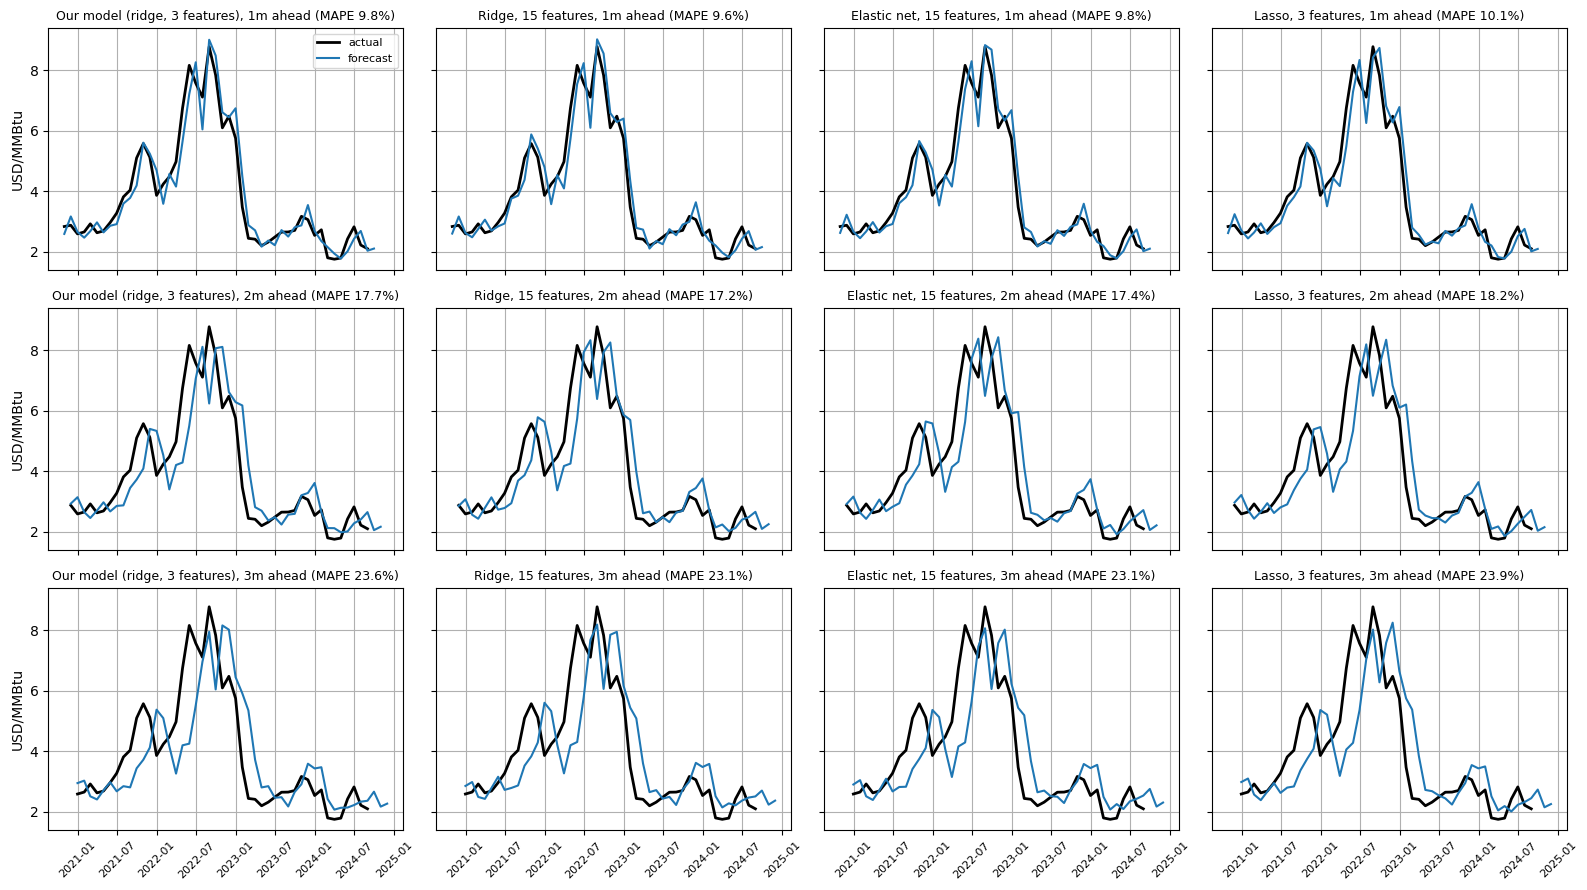

In [20]:
compare = ["Our model (ridge, 3 features)", "Ridge, 15 features", "Elastic net, 15 features", "Lasso, 3 features"]

fig, axes = plt.subplots(3, len(compare), figsize=(16, 9), sharex=True, sharey=True)
for row, h in enumerate(config.HORIZONS):
    target_month = test_dates + pd.offsets.MonthEnd(h)   # plot each forecast at the month it is for
    actual = data["target"].reindex(target_month)
    for col, name in enumerate(compare):
        ax = axes[row, col]
        pred = others[name].loc[test_dates, f"pred_{h}"]
        ax.plot(target_month, actual, color="black", linewidth=2, label="actual")
        ax.plot(target_month, pred, color="tab:blue", label="forecast")
        mape_h = accuracy_table(data, {name: others[name]}, test_dates).loc[name, f"{h}m ahead"]
        ax.set_title(f"{name}, {h}m ahead (MAPE {mape_h:.1f}%)", fontsize=9)
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    axes[row, 0].set_ylabel("USD/MMBtu")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Lasso with 15 features ends up about the same as my model (17.11 vs 17.04 on average). At 1 month it keeps exactly my 3 features and drops the other 12, which I didn't expect. At 2 and 3 months it also keeps storage, production, consumption, the European price and the season.

Ridge and elastic net with all 15 features are a bit better on the test period (16.60 and 16.75), even though on validation ridge with 15 was clearly worse (10.72 vs 8.35). I didn't switch. Picking the model by its test score would mean using the test data for selection, and 0.4 points over 48 months, most of the error coming from 2022, is not a big difference.

My guess is that the validation models only learned from 2003-2012, before the US started exporting LNG in 2016, so storage and the European price didn't tell them much. Trained up to 2020 these features have more useful history. I haven't tested this, but it would be the first thing I'd look at with more data.